# Tata Steel Machine Failure Prediction
## Classification Capstone Project

**Objective:** Predict whether a manufacturing machine is likely to fail using operational parameters.

**Dataset note:** This notebook creates a synthetic dataset based on the failure scenarios in the project brief. It is not actual Tata Steel production data.

### Project workflow
EDA → Data Cleaning → Feature Engineering → Preprocessing → Model Building → Model Comparison → Hyperparameter Tuning → Model Explanation → Prediction → Model Saving

## 1. Install Required Libraries

In [13]:
!pip install -q xgboost lightgbm shap joblib

## 2. Import Libraries

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    roc_curve, precision_recall_curve
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

import shap
import joblib
import warnings

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## 3. Create the Synthetic Dataset

In [15]:
np.random.seed(42)

n = 10000

df = pd.DataFrame({
    "Product_ID": np.arange(1, n + 1),
    "Type": np.random.choice(["Low", "Medium", "High"], size=n, p=[0.30, 0.50, 0.20]),
    "Air_temperature_K": np.random.normal(300, 2, n),
    "Rotational_speed_RPM": np.clip(np.random.normal(1500, 200, n), 1000, 2200),
    "Torque_Nm": np.clip(np.random.normal(40, 10, n), 10, 80),
    "Tool_wear_min": np.random.uniform(0, 250, n)
})

df["Process_temperature_K"] = (
    df["Air_temperature_K"] + np.random.normal(10, 1.5, n)
)

print("Synthetic dataset created:", df.shape)
df.head()

Synthetic dataset created: (10000, 7)


,Product_ID,Type,Air_temperature_K,Rotational_speed_RPM,Torque_Nm,Tool_wear_min,Process_temperature_K
0,1,Medium,297.024,1376.770,47.837,11.534,307.962
1,2,High,297.750,1421.465,40.075,246.077,308.033
2,3,Medium,300.778,1293.635,46.548,89.805,311.255
3,4,Medium,297.652,1322.150,29.857,55.130,308.539
4,5,Low,302.225,1586.875,41.434,122.942,311.322


## 4. Generate Machine Failure Labels

In [16]:
temperature_difference = (
    df["Process_temperature_K"] - df["Air_temperature_K"]
)

power = df["Torque_Nm"] * df["Rotational_speed_RPM"]

tool_wear_failure = df["Tool_wear_min"] > 220

heat_dissipation_failure = (
    (temperature_difference < 8) &
    (df["Rotational_speed_RPM"] < 1300)
)

power_failure = (power < 30000) | (power > 100000)

overstrain_failure = (
    df["Tool_wear_min"] * df["Torque_Nm"] > 2800
)

random_failure = np.random.random(n) < 0.015

df["Machine_failure"] = (
    tool_wear_failure |
    heat_dissipation_failure |
    power_failure |
    overstrain_failure |
    random_failure
).astype(int)

print("Machine failure labels created.")
print(df["Machine_failure"].value_counts())

Machine failure labels created.
Machine_failure
1    7314
0    2686
Name: count, dtype: int64


## 5. Generate Failure Type

In [17]:
def determine_failure_type(row):
    temp_diff = row["Process_temperature_K"] - row["Air_temperature_K"]
    machine_power = row["Torque_Nm"] * row["Rotational_speed_RPM"]

    if row["Tool_wear_min"] > 220:
        return "Tool Wear Failure"
    elif temp_diff < 8 and row["Rotational_speed_RPM"] < 1300:
        return "Heat Dissipation Failure"
    elif machine_power < 30000 or machine_power > 100000:
        return "Power Failure"
    elif row["Tool_wear_min"] * row["Torque_Nm"] > 2800:
        return "Overstrain Failure"
    elif row["Machine_failure"] == 1:
        return "Random Failure"
    return "No Failure"

df["Failure_Type"] = df.apply(determine_failure_type, axis=1)
df.head()

,Product_ID,Type,Air_temperature_K,Rotational_speed_RPM,Torque_Nm,Tool_wear_min,Process_temperature_K,Machine_failure,Failure_Type
0,1,Medium,297.024,1376.770,47.837,11.534,307.962,0,No Failure
1,2,High,297.750,1421.465,40.075,246.077,308.033,1,Tool Wear Failure
2,3,Medium,300.778,1293.635,46.548,89.805,311.255,1,Overstrain Failure
3,4,Medium,297.652,1322.150,29.857,55.130,308.539,0,No Failure
4,5,Low,302.225,1586.875,41.434,122.942,311.322,1,Overstrain Failure


## 6. Save and Reload the CSV

In [18]:
dataset_path = "tata_steel_machine_failure_data.csv"
df.to_csv(dataset_path, index=False)

data = pd.read_csv(dataset_path)

print("CSV saved and loaded successfully.")
print("Shape:", data.shape)
data.head()

CSV saved and loaded successfully.
Shape: (10000, 9)


,Product_ID,Type,Air_temperature_K,Rotational_speed_RPM,Torque_Nm,Tool_wear_min,Process_temperature_K,Machine_failure,Failure_Type
0,1,Medium,297.024,1376.770,47.837,11.534,307.962,0,No Failure
1,2,High,297.750,1421.465,40.075,246.077,308.033,1,Tool Wear Failure
2,3,Medium,300.778,1293.635,46.548,89.805,311.255,1,Overstrain Failure
3,4,Medium,297.652,1322.150,29.857,55.130,308.539,0,No Failure
4,5,Low,302.225,1586.875,41.434,122.942,311.322,1,Overstrain Failure


## 7. Data Quality Checks

In [19]:
print("Shape:", data.shape)
print("\nData types:")
print(data.dtypes)

print("\nMissing values:")
print(data.isnull().sum())

print("\nDuplicate rows:", data.duplicated().sum())

print("\nStatistical summary:")
display(data.describe(include="all"))

Shape: (10000, 9)

Data types:
Product_ID                 int64
Type                      object
Air_temperature_K        float64
Rotational_speed_RPM     float64
Torque_Nm                float64
Tool_wear_min            float64
Process_temperature_K    float64
Machine_failure            int64
Failure_Type              object
dtype: object

Missing values:
Product_ID               0
Type                     0
Air_temperature_K        0
Rotational_speed_RPM     0
Torque_Nm                0
Tool_wear_min            0
Process_temperature_K    0
Machine_failure          0
Failure_Type             0
dtype: int64

Duplicate rows: 0

Statistical summary:


,Product_ID,Type,Air_temperature_K,Rotational_speed_RPM,Torque_Nm,Tool_wear_min,Process_temperature_K,Machine_failure,Failure_Type
count,10000.000,10000,10000.000,10000.000,10000.000,10000.000,10000.000,10000.000,10000
unique,NaN,3,NaN,NaN,NaN,NaN,NaN,NaN,6
top,NaN,Medium,NaN,NaN,NaN,NaN,NaN,NaN,Overstrain Failure
freq,NaN,4985,NaN,NaN,NaN,NaN,NaN,NaN,5594
mean,5000.500,NaN,300.025,1500.001,39.805,125.386,310.016,0.731,NaN
std,2886.896,NaN,2.000,197.018,10.035,71.746,2.511,0.443,NaN
min,1.000,NaN,292.155,1000.000,10.000,0.002,300.815,0.000,NaN
25%,2500.750,NaN,298.683,1362.794,32.911,63.960,308.328,0.000,NaN
50%,5000.500,NaN,300.034,1499.970,39.827,126.205,310.041,1.000,NaN
75%,7500.250,NaN,301.365,1634.875,46.733,187.162,311.704,1.000,NaN


## 8. Target Distribution

Machine Failure Counts:


,count
Machine_failure,
1,7314
0,2686



Machine Failure Percentage:


,proportion
Machine_failure,
1,73.140
0,26.860


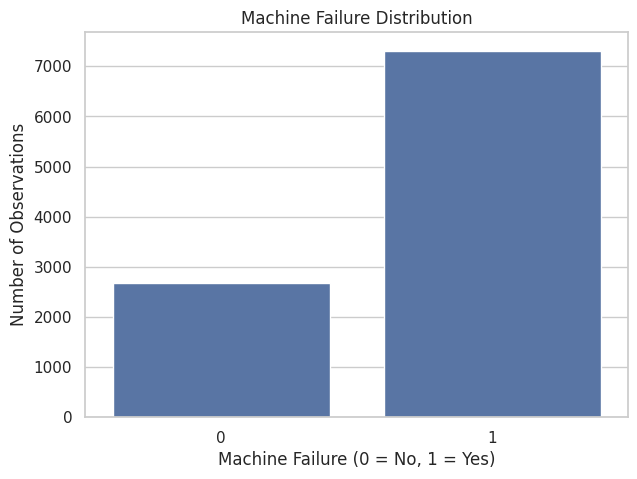

In [20]:
print("Machine Failure Counts:")
display(data["Machine_failure"].value_counts())

print("\nMachine Failure Percentage:")
display(data["Machine_failure"].value_counts(normalize=True).mul(100).round(2))

plt.figure(figsize=(7, 5))
sns.countplot(data=data, x="Machine_failure")
plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Number of Observations")
plt.show()

## 9. Exploratory Data Analysis — Product Type

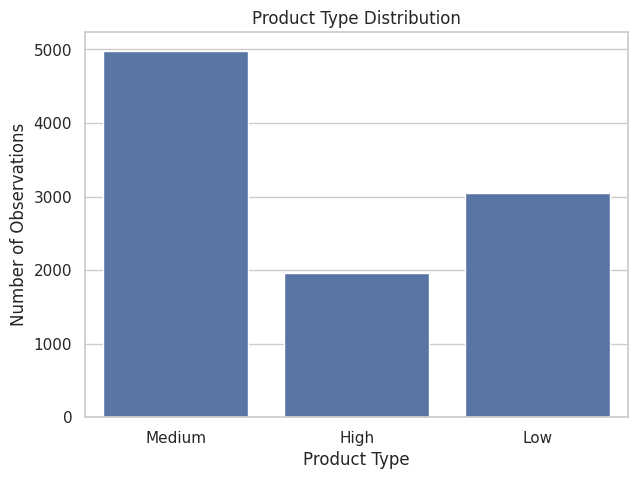

Failure rate by product type:


,Failure Rate (%)
Type,
High,75.230
Low,72.190
Medium,72.900


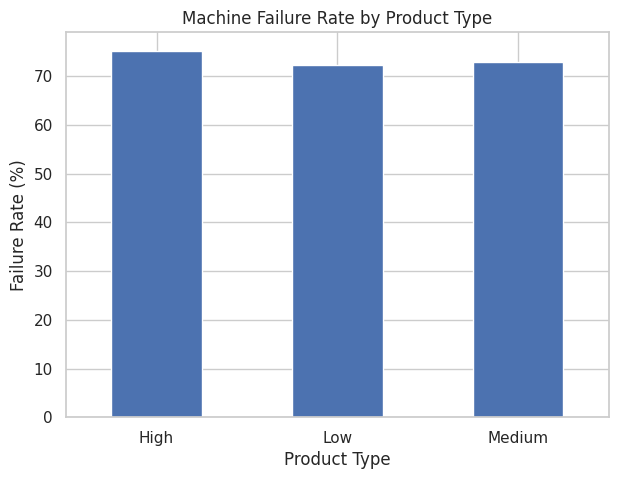

In [21]:
plt.figure(figsize=(7, 5))
sns.countplot(data=data, x="Type")
plt.title("Product Type Distribution")
plt.xlabel("Product Type")
plt.ylabel("Number of Observations")
plt.show()

failure_by_type = data.groupby("Type")["Machine_failure"].mean().mul(100)

print("Failure rate by product type:")
display(failure_by_type.round(2).to_frame("Failure Rate (%)"))

plt.figure(figsize=(7, 5))
failure_by_type.plot(kind="bar")
plt.title("Machine Failure Rate by Product Type")
plt.xlabel("Product Type")
plt.ylabel("Failure Rate (%)")
plt.xticks(rotation=0)
plt.show()

## 10. Failure Type Analysis

,Count
Failure_Type,
Overstrain Failure,5594
No Failure,2686
Tool Wear Failure,1167
Power Failure,378
Heat Dissipation Failure,138
Random Failure,37


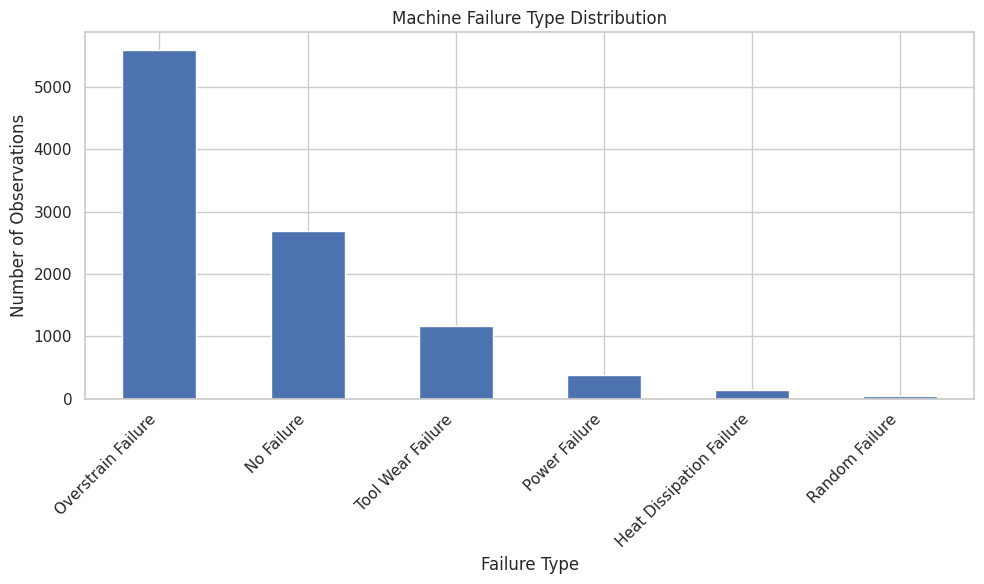

In [22]:
failure_types = data["Failure_Type"].value_counts()
display(failure_types.to_frame("Count"))

plt.figure(figsize=(10, 6))
failure_types.plot(kind="bar")
plt.title("Machine Failure Type Distribution")
plt.xlabel("Failure Type")
plt.ylabel("Number of Observations")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 11. Numerical Feature Distributions

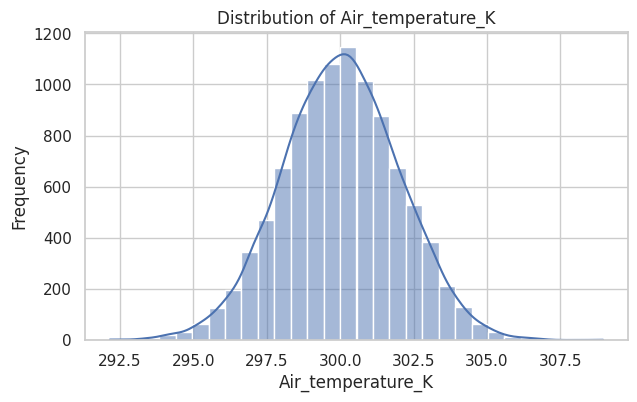

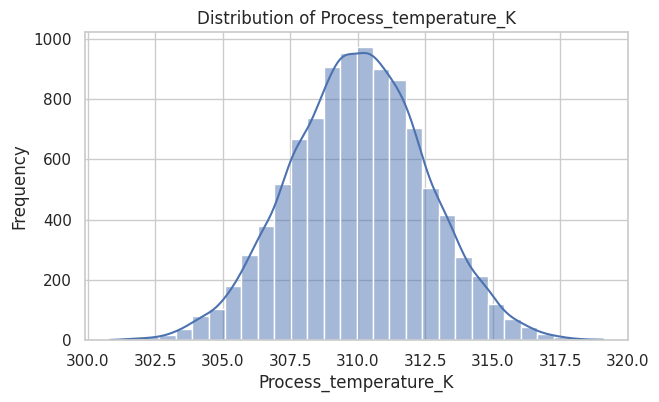

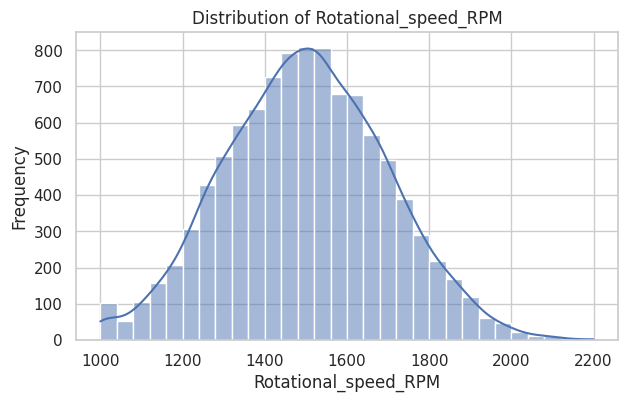

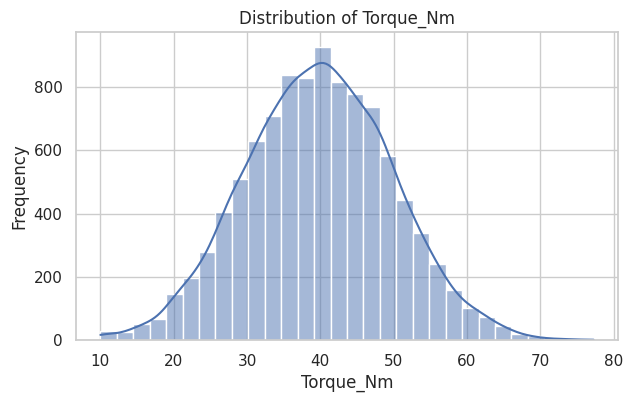

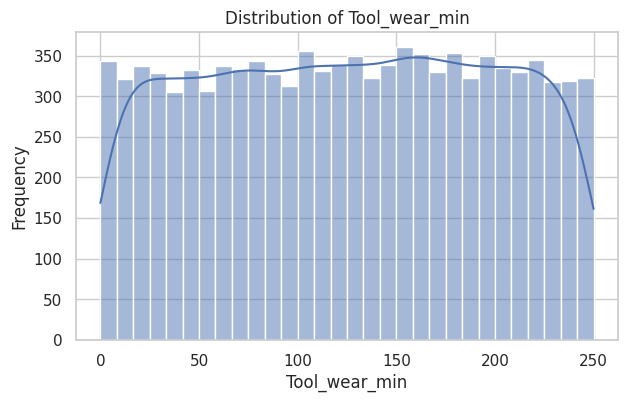

In [23]:
numerical_features_original = [
    "Air_temperature_K",
    "Process_temperature_K",
    "Rotational_speed_RPM",
    "Torque_Nm",
    "Tool_wear_min"
]

for column in numerical_features_original:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=data, x=column, kde=True, bins=30)
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.show()

## 12. Boxplots for Outlier Inspection

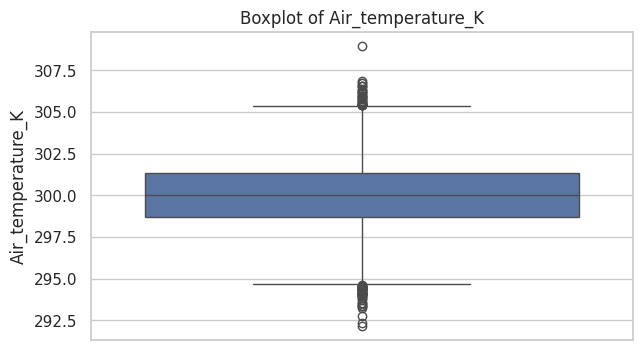

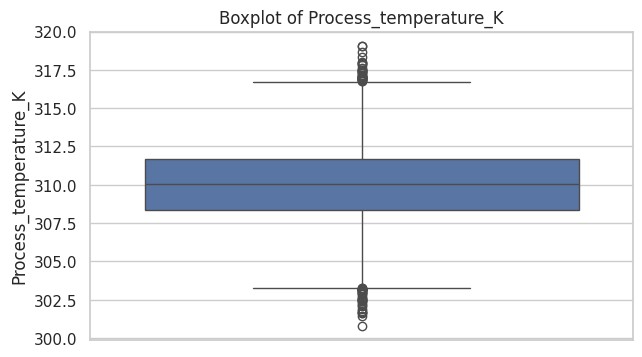

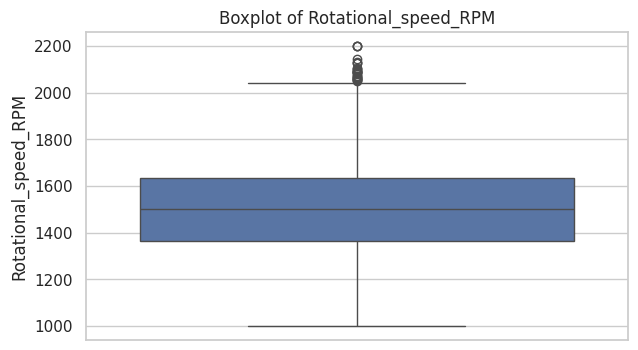

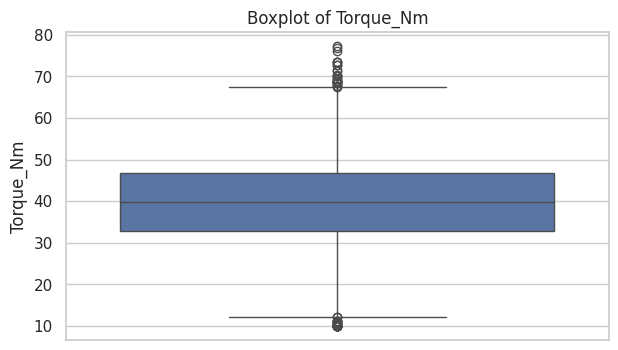

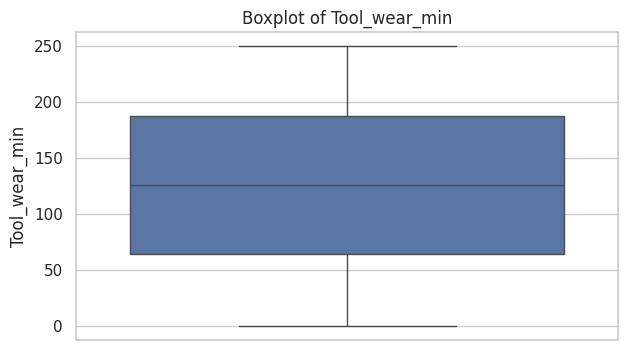

In [24]:
for column in numerical_features_original:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=data, y=column)
    plt.title(f"Boxplot of {column}")
    plt.show()

## 13. Correlation Analysis

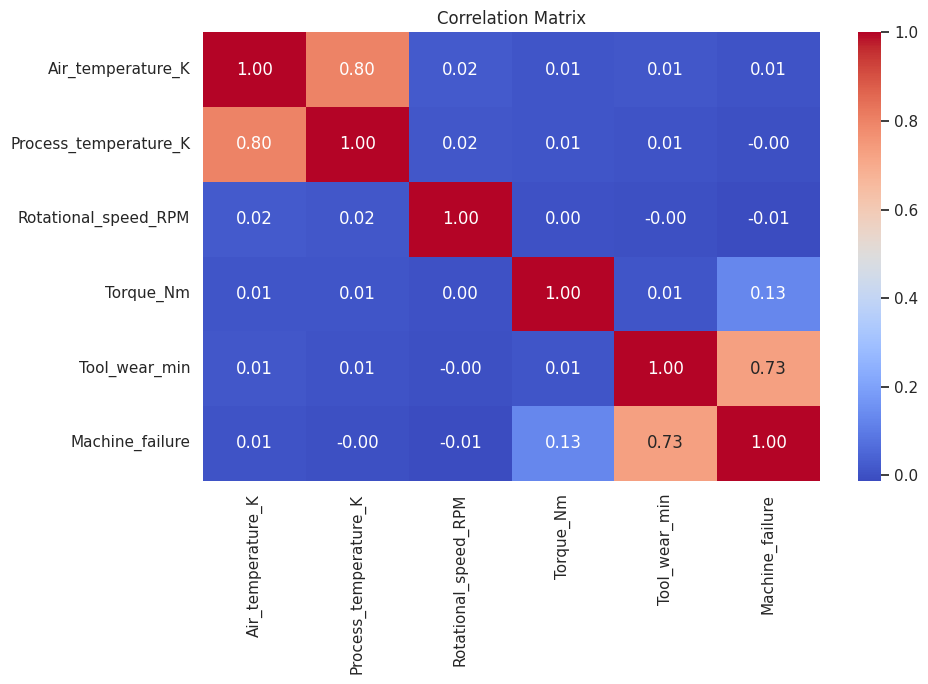

In [25]:
correlation_features = numerical_features_original + ["Machine_failure"]
correlation_matrix = data[correlation_features].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

## 14. Failure vs Key Operational Variables

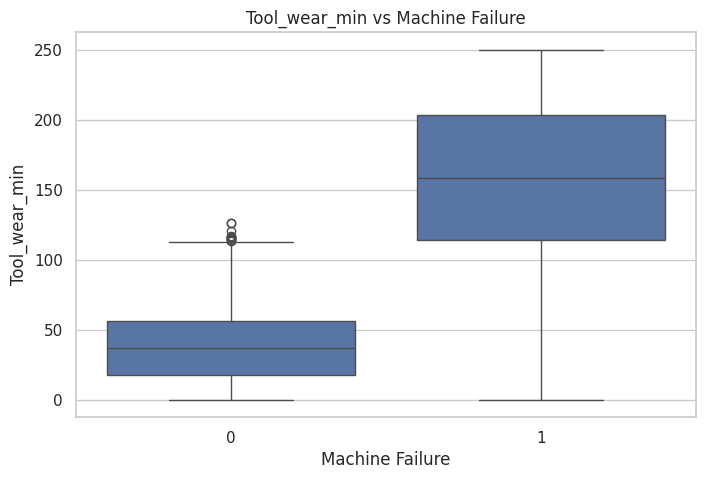

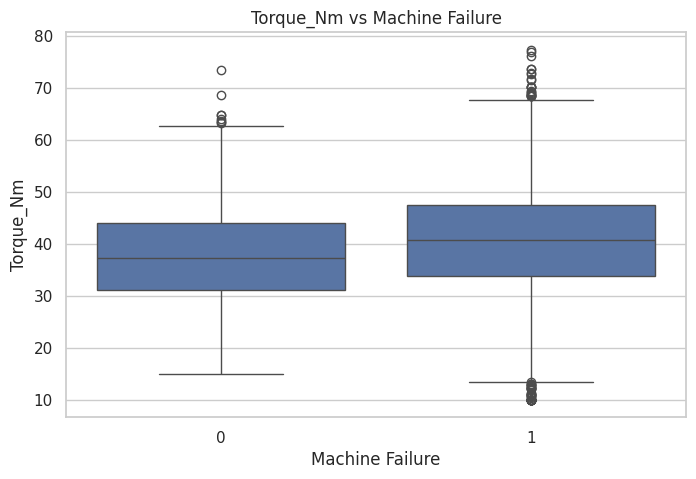

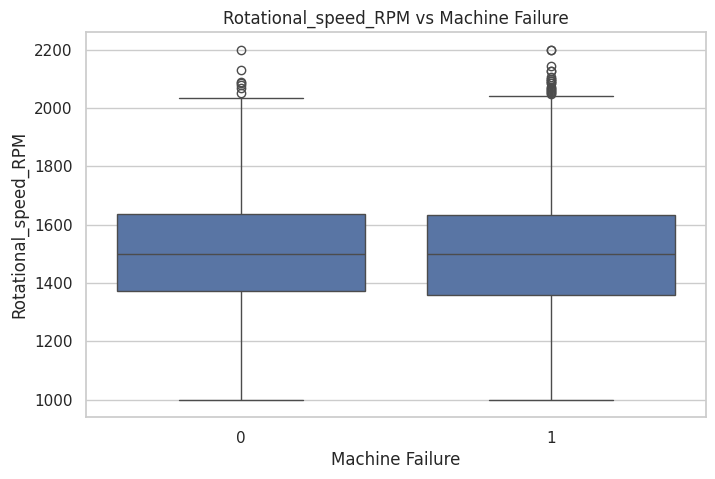

In [26]:
for column in ["Tool_wear_min", "Torque_Nm", "Rotational_speed_RPM"]:
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=data, x="Machine_failure", y=column)
    plt.title(f"{column} vs Machine Failure")
    plt.xlabel("Machine Failure")
    plt.ylabel(column)
    plt.show()

## 15. Feature Engineering

In [27]:
data["Temperature_Difference"] = (
    data["Process_temperature_K"] - data["Air_temperature_K"]
)

data["Power"] = (
    data["Torque_Nm"] * data["Rotational_speed_RPM"]
)

data["ToolWear_Torque"] = (
    data["Tool_wear_min"] * data["Torque_Nm"]
)

engineered_features = [
    "Temperature_Difference",
    "Power",
    "ToolWear_Torque"
]

display(data[engineered_features].describe())

,Temperature_Difference,Power,ToolWear_Torque
count,10000.000,10000.000,10000.000
mean,9.991,59712.689,4997.357
std,1.511,17079.521,3207.948
min,4.868,10149.034,0.097
25%,8.983,47756.761,2355.569
50%,10.001,58867.793,4669.792
75%,11.007,70762.800,7238.972
max,15.618,135981.477,18949.511


## 16. Engineered Feature Visualization

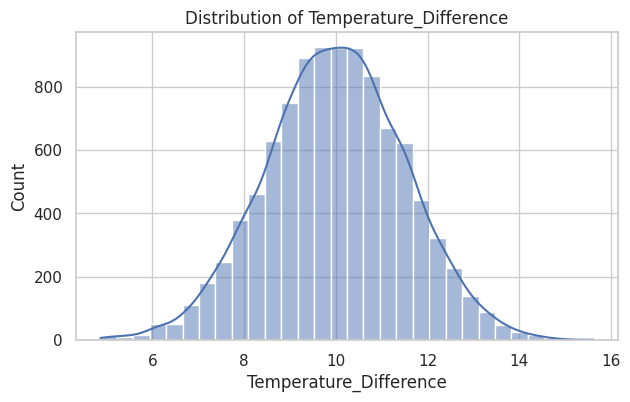

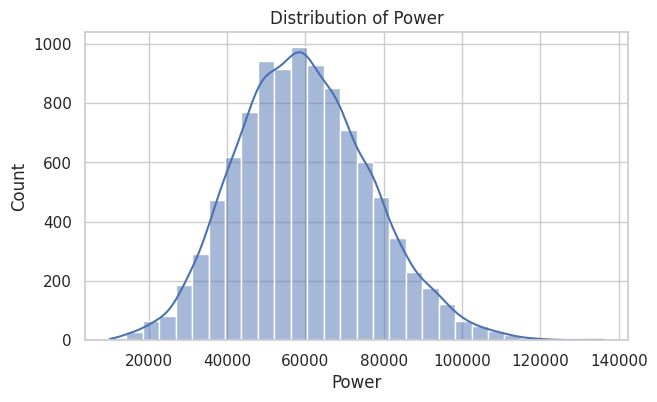

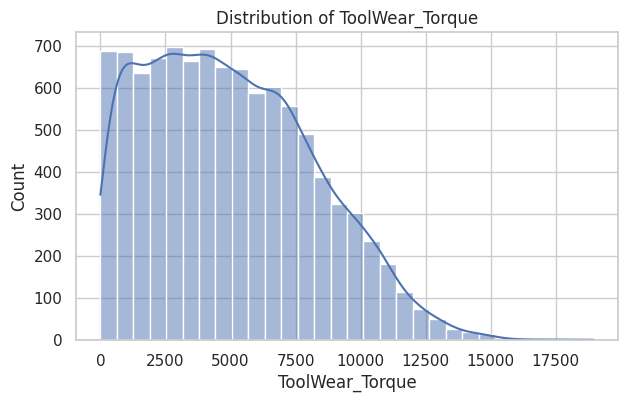

In [28]:
for column in engineered_features:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=data, x=column, kde=True, bins=30)
    plt.title(f"Distribution of {column}")
    plt.show()

## 17. Prepare Features and Target

In [29]:
# Product_ID is only an identifier.
# Failure_Type is derived from the target and would cause target leakage.

X = data.drop(columns=["Machine_failure", "Failure_Type", "Product_ID"])
y = data["Machine_failure"]

categorical_features = ["Type"]

numerical_features = [
    "Air_temperature_K",
    "Process_temperature_K",
    "Rotational_speed_RPM",
    "Torque_Nm",
    "Tool_wear_min",
    "Temperature_Difference",
    "Power",
    "ToolWear_Torque"
]

print("Features:", X.columns.tolist())
print("Target:", y.name)

Features: ['Type', 'Air_temperature_K', 'Rotational_speed_RPM', 'Torque_Nm', 'Tool_wear_min', 'Process_temperature_K', 'Temperature_Difference', 'Power', 'ToolWear_Torque']
Target: Machine_failure


## 18. Train-Test Split

In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (8000, 9)
Testing set: (2000, 9)


## 19. Preprocessing Pipeline

In [31]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


## 20. Evaluation Function

In [32]:
def evaluate_model(model_name, y_true, y_pred, y_probability):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1 Score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_probability)
    }

results = []

## 21. Logistic Regression

In [33]:
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

y_pred_lr = logistic_model.predict(X_test)
y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

results.append(evaluate_model(
    "Logistic Regression", y_test, y_pred_lr, y_prob_lr
))

print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.88      0.99      0.93       537
           1       1.00      0.95      0.97      1463

    accuracy                           0.96      2000
   macro avg       0.94      0.97      0.95      2000
weighted avg       0.96      0.96      0.96      2000



## 22. Decision Tree

In [34]:
decision_tree = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        class_weight="balanced",
        max_depth=8,
        random_state=42
    ))
])

decision_tree.fit(X_train, y_train)

y_pred_dt = decision_tree.predict(X_test)
y_prob_dt = decision_tree.predict_proba(X_test)[:, 1]

results.append(evaluate_model(
    "Decision Tree", y_test, y_pred_dt, y_prob_dt
))

print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       0.98      1.00      0.99       537
           1       1.00      0.99      1.00      1463

    accuracy                           0.99      2000
   macro avg       0.99      0.99      0.99      2000
weighted avg       0.99      0.99      0.99      2000



## 23. Random Forest

In [35]:
random_forest = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

random_forest.fit(X_train, y_train)

y_pred_rf = random_forest.predict(X_test)
y_prob_rf = random_forest.predict_proba(X_test)[:, 1]

results.append(evaluate_model(
    "Random Forest", y_test, y_pred_rf, y_prob_rf
))

print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.97      1.00      0.99       537
           1       1.00      0.99      1.00      1463

    accuracy                           0.99      2000
   macro avg       0.99      1.00      0.99      2000
weighted avg       0.99      0.99      0.99      2000



## 24. XGBoost

In [36]:
xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42
    ))
])

xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

results.append(evaluate_model(
    "XGBoost", y_test, y_pred_xgb, y_prob_xgb
))

print(classification_report(y_test, y_pred_xgb))

              precision    recall  f1-score   support

           0       0.97      1.00      0.98       537
           1       1.00      0.99      0.99      1463

    accuracy                           0.99      2000
   macro avg       0.99      0.99      0.99      2000
weighted avg       0.99      0.99      0.99      2000



## 25. LightGBM

In [37]:
lgbm_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        num_leaves=31,
        random_state=42,
        verbosity=-1
    ))
])

lgbm_model.fit(X_train, y_train)

y_pred_lgbm = lgbm_model.predict(X_test)
y_prob_lgbm = lgbm_model.predict_proba(X_test)[:, 1]

results.append(evaluate_model(
    "LightGBM", y_test, y_pred_lgbm, y_prob_lgbm
))

print(classification_report(y_test, y_pred_lgbm))

              precision    recall  f1-score   support

           0       0.97      1.00      0.98       537
           1       1.00      0.99      0.99      1463

    accuracy                           0.99      2000
   macro avg       0.98      0.99      0.99      2000
weighted avg       0.99      0.99      0.99      2000



## 26. Model Comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Decision Tree,0.993,0.999,0.991,0.995,0.995
1,Random Forest,0.993,1.000,0.990,0.995,0.996
2,XGBoost,0.992,0.999,0.990,0.994,0.996
3,LightGBM,0.991,0.999,0.989,0.994,0.996
4,Logistic Regression,0.960,0.997,0.948,0.972,0.981


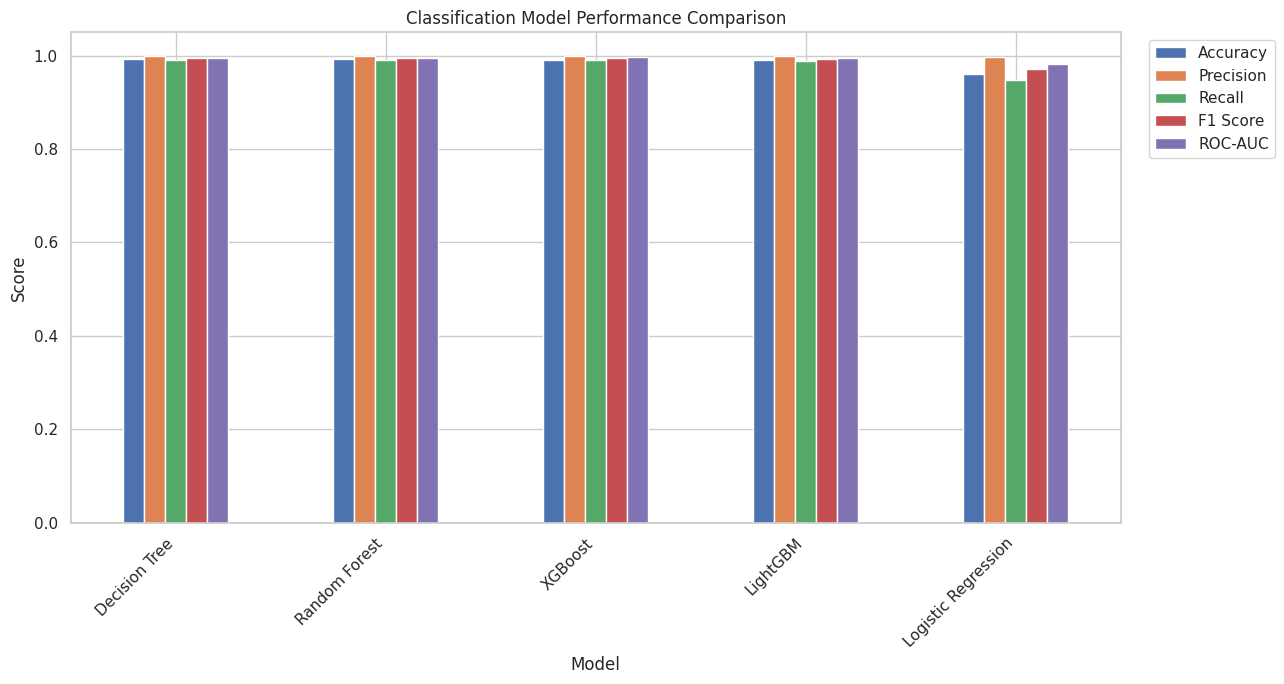

In [38]:
results_df = pd.DataFrame(results).sort_values(
    by="F1 Score", ascending=False
).reset_index(drop=True)

display(results_df)

results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
].plot(kind="bar", figsize=(13, 7))

plt.title("Classification Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1.05)
plt.xticks(rotation=45, ha="right")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 27. Confusion Matrices

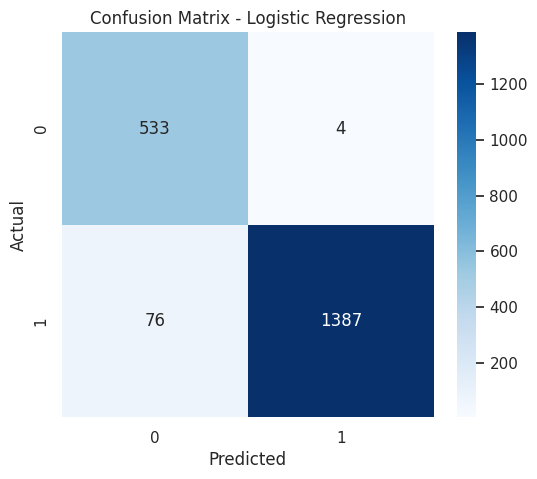

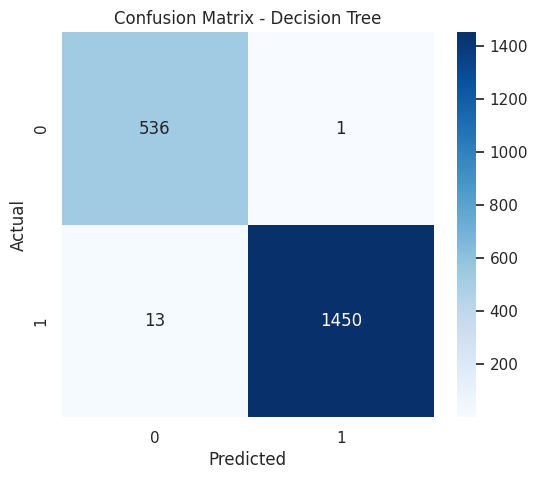

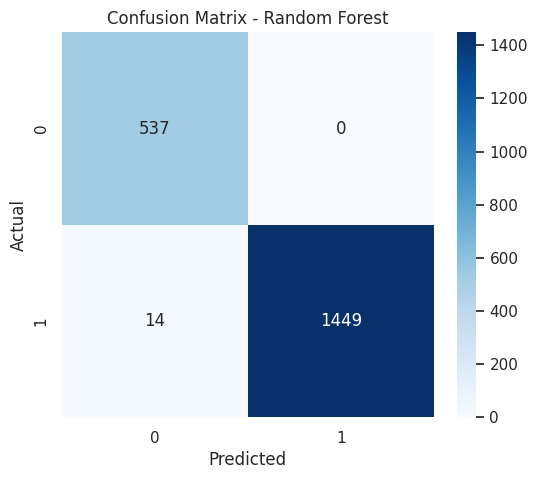

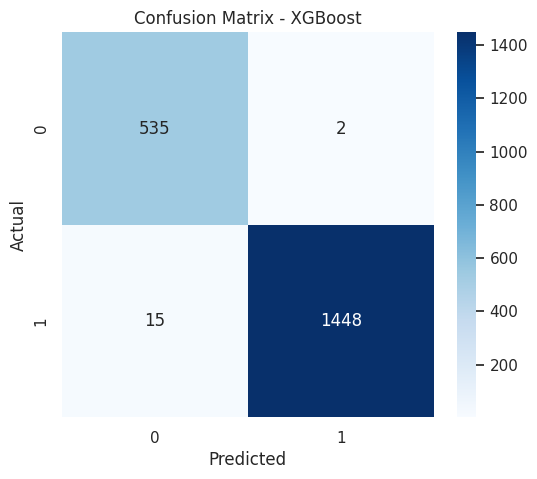

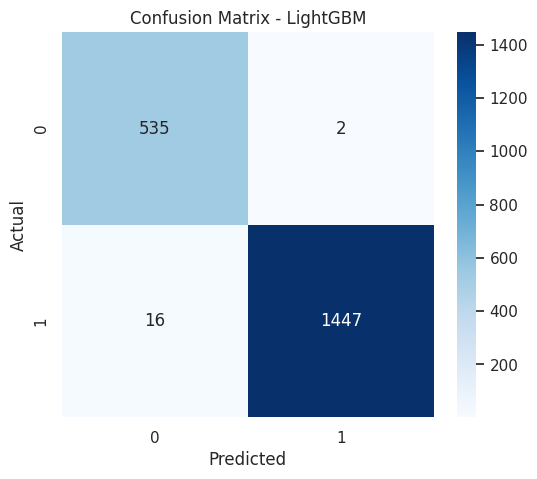

In [39]:
model_predictions = {
    "Logistic Regression": y_pred_lr,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "XGBoost": y_pred_xgb,
    "LightGBM": y_pred_lgbm
}

for model_name, predictions in model_predictions.items():
    cm = confusion_matrix(y_test, predictions)

    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

## 28. ROC Curve Comparison

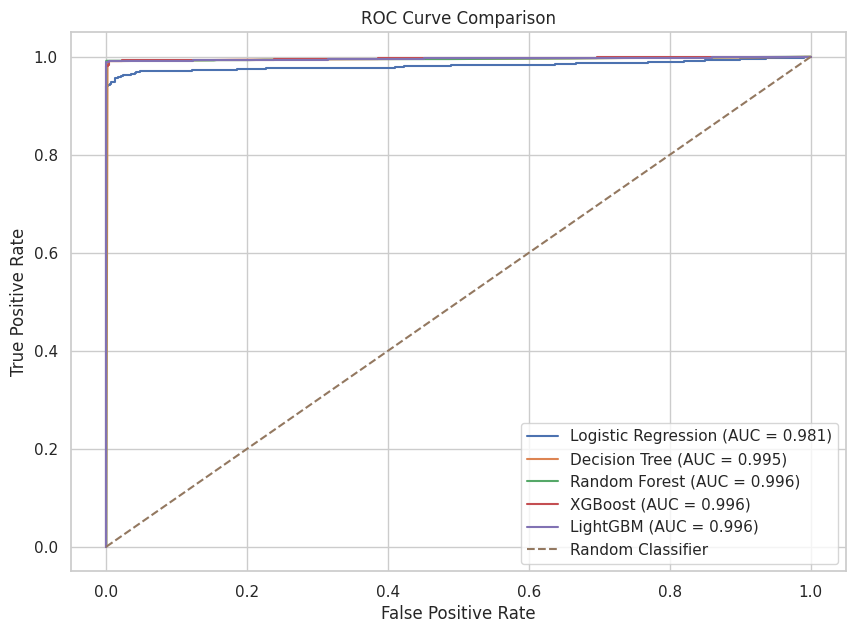

In [40]:
model_probabilities = {
    "Logistic Regression": y_prob_lr,
    "Decision Tree": y_prob_dt,
    "Random Forest": y_prob_rf,
    "XGBoost": y_prob_xgb,
    "LightGBM": y_prob_lgbm
}

plt.figure(figsize=(10, 7))

for model_name, probabilities in model_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc_score = roc_auc_score(y_test, probabilities)

    plt.plot(
        fpr, tpr,
        label=f"{model_name} (AUC = {auc_score:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

## 29. Precision-Recall Curve Comparison

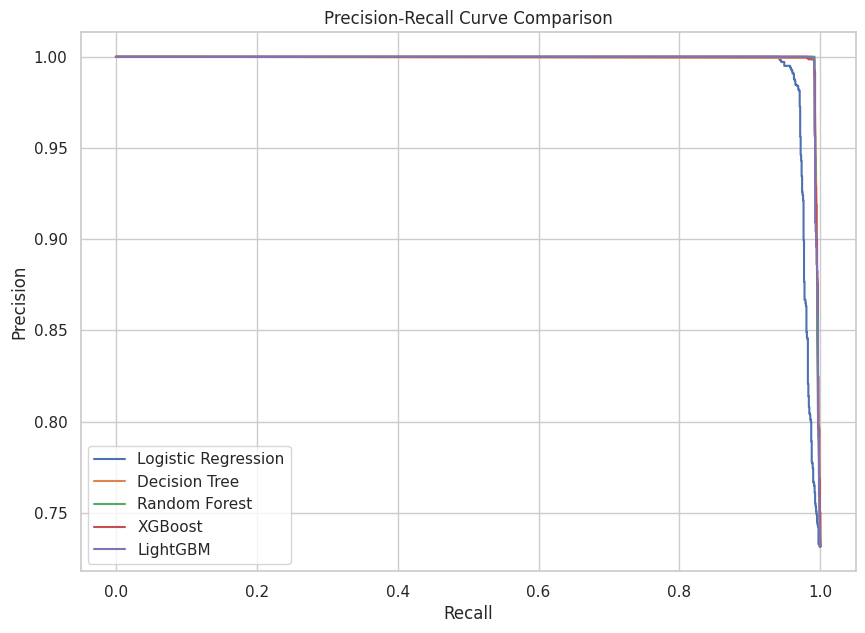

In [41]:
plt.figure(figsize=(10, 7))

for model_name, probabilities in model_probabilities.items():
    precision, recall, _ = precision_recall_curve(
        y_test, probabilities
    )
    plt.plot(recall, precision, label=model_name)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")
plt.legend()
plt.show()

## 30. Hyperparameter Tuning — Random Forest

In [ ]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

param_grid = {
    "classifier__n_estimators": [200, 300],
    "classifier__max_depth": [5, 8, 12],
    "classifier__min_samples_split": [2, 5]
}

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)
print("\nBest CV F1:", grid_search.best_score_)

Fitting 5 folds for each of 12 candidates, totalling 60 fits


## 31. Evaluate Tuned Random Forest

In [ ]:
best_rf = grid_search.best_estimator_

y_pred_best = best_rf.predict(X_test)
y_prob_best = best_rf.predict_proba(X_test)[:, 1]

tuned_result = evaluate_model(
    "Tuned Random Forest",
    y_test,
    y_pred_best,
    y_prob_best
)

print(classification_report(y_test, y_pred_best))
display(pd.DataFrame([tuned_result]))

## 32. Final Model Comparison

In [ ]:
final_results = results.copy()
final_results.append(tuned_result)

final_results_df = pd.DataFrame(final_results).sort_values(
    by="F1 Score", ascending=False
).reset_index(drop=True)

display(final_results_df)

final_results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
].plot(kind="bar", figsize=(14, 7))

plt.title("Final Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1.05)
plt.xticks(rotation=45, ha="right")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 33. Cross Validation

In [ ]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    best_rf,
    X_train,
    y_train,
    cv=cv,
    scoring="f1"
)

print("Cross-validation F1 scores:", cv_scores)
print("Mean CV F1:", cv_scores.mean())
print("Standard deviation:", cv_scores.std())

## 34. Final Confusion Matrix and ROC Curve

In [ ]:
cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Final Model Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

fpr, tpr, _ = roc_curve(y_test, y_prob_best)
auc_score = roc_auc_score(y_test, y_prob_best)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"Tuned Random Forest (AUC = {auc_score:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Final Model")
plt.legend()
plt.show()

## 35. Feature Importance

In [ ]:
fitted_preprocessor = best_rf.named_steps["preprocessor"]
final_classifier = best_rf.named_steps["classifier"]

feature_names = fitted_preprocessor.get_feature_names_out()
importance_values = final_classifier.feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
}).sort_values(
    by="Importance", ascending=False
).reset_index(drop=True)

display(feature_importance_df.head(15))

## 36. Feature Importance Chart

In [ ]:
top_features = feature_importance_df.head(15)

plt.figure(figsize=(10, 7))
sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)
plt.title("Top Features Influencing Machine Failure")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 37. SHAP Explainability

In [ ]:
X_test_transformed = fitted_preprocessor.transform(X_test)

if hasattr(X_test_transformed, "toarray"):
    X_test_transformed = X_test_transformed.toarray()

explainer = shap.TreeExplainer(final_classifier)
shap_values = explainer.shap_values(X_test_transformed)

if isinstance(shap_values, list):
    shap_values_for_plot = shap_values[1]
else:
    shap_values_for_plot = shap_values

print("SHAP values generated successfully.")

## 38. SHAP Summary Plot

In [ ]:
shap.summary_plot(
    shap_values_for_plot,
    X_test_transformed,
    feature_names=feature_names
)

## 39. SHAP Feature Importance

In [ ]:
shap.summary_plot(
    shap_values_for_plot,
    X_test_transformed,
    feature_names=feature_names,
    plot_type="bar"
)

## 40. Test an Individual Machine

In [ ]:
new_machine = pd.DataFrame({
    "Type": ["Medium"],
    "Air_temperature_K": [302],
    "Process_temperature_K": [311],
    "Rotational_speed_RPM": [1200],
    "Torque_Nm": [65],
    "Tool_wear_min": [230]
})

new_machine["Temperature_Difference"] = (
    new_machine["Process_temperature_K"] -
    new_machine["Air_temperature_K"]
)

new_machine["Power"] = (
    new_machine["Torque_Nm"] *
    new_machine["Rotational_speed_RPM"]
)

new_machine["ToolWear_Torque"] = (
    new_machine["Tool_wear_min"] *
    new_machine["Torque_Nm"]
)

display(new_machine)

## 41. Machine Failure Prediction

In [ ]:
prediction = best_rf.predict(new_machine)[0]
failure_probability = best_rf.predict_proba(new_machine)[0, 1]

print("Prediction:", "Machine Failure" if prediction == 1 else "No Machine Failure")
print(f"Failure Probability: {failure_probability:.2%}")

## 42. Risk Category and Maintenance Recommendation

In [ ]:
def risk_category(probability):
    if probability < 0.30:
        return "Low Risk"
    elif probability < 0.60:
        return "Medium Risk"
    return "High Risk"

risk = risk_category(failure_probability)

if risk == "High Risk":
    recommendation = (
        "Schedule preventive maintenance immediately. "
        "Inspect tool wear, torque, rotational speed, "
        "temperature conditions, and mechanical power."
    )
elif risk == "Medium Risk":
    recommendation = (
        "Increase machine monitoring frequency and "
        "schedule preventive inspection."
    )
else:
    recommendation = (
        "Continue normal monitoring and planned maintenance."
    )

print("Risk Category:", risk)
print("Recommendation:", recommendation)

## 43. Reusable Prediction Function

In [ ]:
def predict_machine_failure(
    model,
    product_type,
    air_temperature,
    process_temperature,
    rotational_speed,
    torque,
    tool_wear
):
    machine = pd.DataFrame({
        "Type": [product_type],
        "Air_temperature_K": [air_temperature],
        "Process_temperature_K": [process_temperature],
        "Rotational_speed_RPM": [rotational_speed],
        "Torque_Nm": [torque],
        "Tool_wear_min": [tool_wear]
    })

    machine["Temperature_Difference"] = (
        machine["Process_temperature_K"] -
        machine["Air_temperature_K"]
    )

    machine["Power"] = (
        machine["Torque_Nm"] *
        machine["Rotational_speed_RPM"]
    )

    machine["ToolWear_Torque"] = (
        machine["Tool_wear_min"] *
        machine["Torque_Nm"]
    )

    prediction = model.predict(machine)[0]
    probability = model.predict_proba(machine)[0, 1]

    return {
        "Prediction": int(prediction),
        "Failure_Probability": float(probability),
        "Risk_Category": risk_category(probability)
    }

result = predict_machine_failure(
    best_rf,
    "High",
    303,
    312,
    1150,
    68,
    235
)

print(result)

## 44. Save Final Model and Project Outputs

In [ ]:
joblib.dump(best_rf, "machine_failure_model.pkl")

final_results_df.to_csv(
    "model_comparison_results.csv",
    index=False
)

feature_importance_df.to_csv(
    "feature_importance.csv",
    index=False
)

pd.DataFrame({
    "Feature": X.columns
}).to_csv(
    "model_features.csv",
    index=False
)

print("Saved files:")
print("1. tata_steel_machine_failure_data.csv")
print("2. machine_failure_model.pkl")
print("3. model_comparison_results.csv")
print("4. feature_importance.csv")
print("5. model_features.csv")

## 45. Verify Saved Model

In [ ]:
loaded_model = joblib.load("machine_failure_model.pkl")

loaded_prediction = loaded_model.predict(new_machine)[0]
loaded_probability = loaded_model.predict_proba(new_machine)[0, 1]

print("Loaded model prediction:", loaded_prediction)
print(f"Loaded model failure probability: {loaded_probability:.2%}")

## 46. Final Project Summary

### Business Problem
Unexpected machine failures can cause production downtime, maintenance costs, and quality issues. The objective is to use machine-learning classification to identify machines at risk of failure.

### Solution
The project generates a synthetic manufacturing dataset, performs exploratory analysis and feature engineering, compares multiple classification algorithms, tunes a Random Forest model, explains predictions using feature importance and SHAP, and saves the final model for deployment.

### Models
- Logistic Regression
- Decision Tree
- Random Forest
- XGBoost
- LightGBM
- Tuned Random Forest

### Evaluation Metrics
- Accuracy
- Precision
- Recall
- F1 Score
- ROC-AUC

### Deployment
The saved `machine_failure_model.pkl` can be used later in a Streamlit application for interactive machine-failure prediction.